# Lab 3 demo: churn model → retention offers (Track B)

End to end in one run:

1. **Task 1:** load the registered XGBoost churn model, rebuild customer features from raw transactions, and score every customer.
2. **Track B:** take customers the model flags as at risk and generate a policy-grounded retention offer for them with the RAG pipeline (`offer_generation/`).
3. **Evaluation:** summarize the RAGAS harness runs saved in `docs/lab3-evidence/rag_eval.csv`.

Needs AWS credentials with Bedrock access (Titan embeddings + Claude Haiku 4.5). Nothing else in AWS has to be running.

In [1]:
import json
import sys
from pathlib import Path

import boto3
import numpy as np
import pandas as pd
import xgboost as xgb
from IPython.display import Image, display
from sklearn.metrics import roc_auc_score

REPO_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(REPO_ROOT))
pd.set_option("display.width", 160)

print("repo:", REPO_ROOT)
print("aws account:", boto3.client("sts").get_caller_identity()["Account"])

repo: C:\Users\joell\401r\cs401r-jmedw857


aws account: 860366539138


## Task 1: churn model

### The registered model and its final evaluation
These metrics come from the graded `--register` training run (see `docs/lab3-evidence/train-final.log`).

In [2]:
meta = json.loads((REPO_ROOT / "model/final/model_metadata.json").read_text())
model = xgb.Booster()
model.load_model(str(REPO_ROOT / "model/final/model.xgb"))

print("hyperparameters:", meta["hyperparameters"])
print("features:", len(meta["feature_columns"]))
pd.Series(meta["evaluation_metrics"]).to_frame("value")

hyperparameters: {'max_depth': 4, 'eta': 0.05, 'num_round': 200}
features: 11


C:\Users\joell\AppData\Local\Temp\ipykernel_25904\570118444.py:3: UserWarning: [19:51:47] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\c_api\c_api.cc:1489: Unknown file format: `xgb`. Using UBJSON (`ubj`) as a guess.
  model.load_model(str(REPO_ROOT / "model/final/model.xgb"))


,value
auc_roc,0.7829
precision_top10,0.7167
recall_top10,0.3258
auc_vs_baseline,0.0603
baseline_auc,0.7226
lift_ci_low,0.0415
lift_ci_high,0.0796
positive_rate_val,0.22
n_val_samples,3000
eval_timestamp,2026-10-14T23:43:27.959461


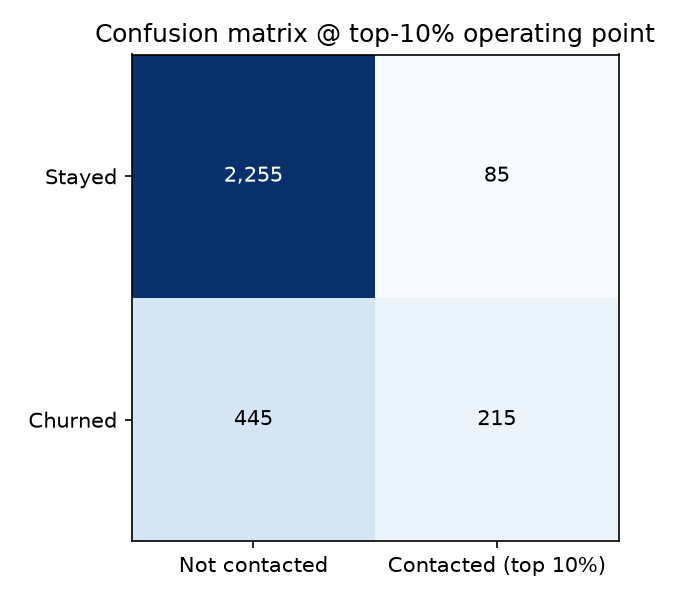

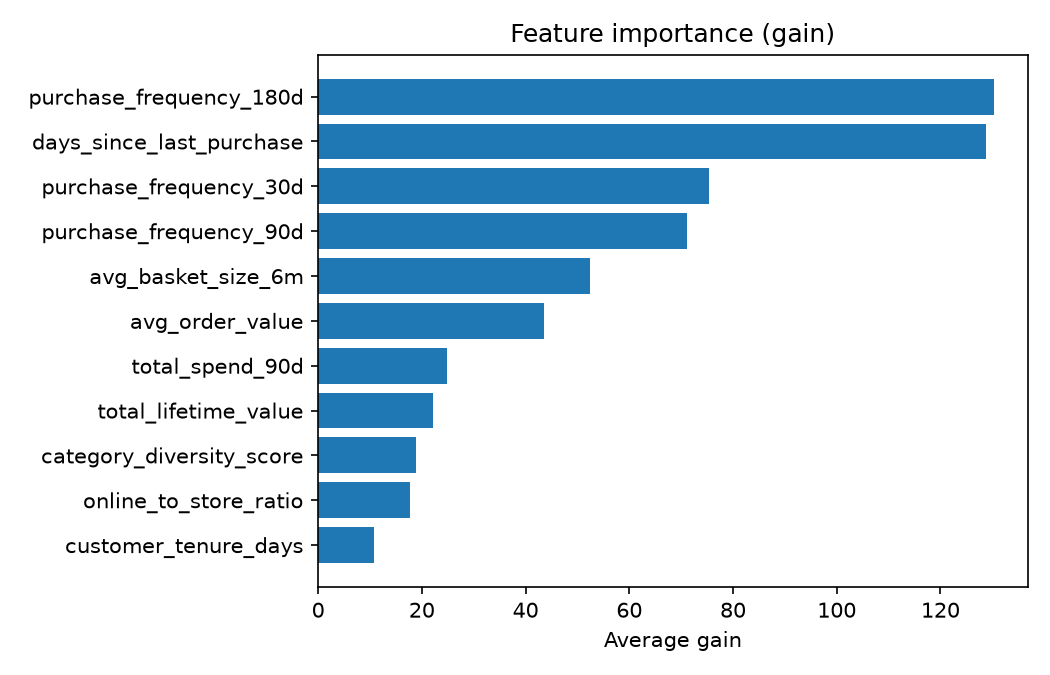

In [3]:
display(Image(filename=str(REPO_ROOT / "docs/lab3-evidence/confusion-matrix.png"), width=420))
display(Image(filename=str(REPO_ROOT / "docs/lab3-evidence/feature-importance.png"), width=520))

### Rebuild features from raw transactions
The Lab 2 feature store has been torn down, so this applies the same cleaning (`glue-scripts/transform.py`) and the same feature definitions (`glue-scripts/feature_engineer.py`) to `northstar-raw-sample.csv` in pandas. The temporal split is the same as Lab 2: features use only purchases on or before the cutoff, and the churn label comes only from the holdout window.

In [4]:
FEATURE_CUTOFF = pd.Timestamp("2026-04-01")
SNAPSHOT = pd.Timestamp("2026-06-30")

raw = pd.read_csv(REPO_ROOT / "northstar-raw-sample.csv")

# transform.py: trim text columns, drop missing customer ids, parse both date formats,
# median-impute numerics, 'unknown' for strings, dedupe transaction ids
tx = raw.copy()
for c in tx.select_dtypes(exclude="number").columns:   # trim every text column, "" -> null
    tx[c] = tx[c].str.strip().replace("", np.nan)
tx = tx.dropna(subset=["customer_id"])
tx["purchase_date"] = (pd.to_datetime(tx.purchase_date, format="%Y-%m-%d", errors="coerce")
                         .fillna(pd.to_datetime(tx.purchase_date, format="%m/%d/%Y", errors="coerce")))
tx = tx.dropna(subset=["purchase_date"])
for c in ["order_value", "num_items"]:
    tx[c] = tx[c].fillna(tx[c].median())
tx["product_category"] = tx["product_category"].fillna("unknown")
tx = (tx.sort_values(["transaction_id", "purchase_date", "order_value"], ascending=[True, False, False])
        .drop_duplicates("transaction_id"))

history = tx[tx.purchase_date <= FEATURE_CUTOFF].copy()
holdout = tx[(tx.purchase_date > FEATURE_CUTOFF) & (tx.purchase_date <= SNAPSHOT)]
print(f"{len(raw):,} raw rows -> {len(tx):,} clean; history {len(history):,}, holdout {len(holdout):,}")

163,255 raw rows -> 157,627 clean; history 130,189, holdout 27,438


In [5]:
# feature_engineer.py, one row per customer
history["days_ago"] = (FEATURE_CUTOFF - history.purchase_date).dt.days
g = history.groupby("customer_id")
last180 = history[history.days_ago < 180].groupby("customer_id")

features = pd.DataFrame({
    "days_since_last_purchase": (FEATURE_CUTOFF - g.purchase_date.max()).dt.days,
    "customer_tenure_days": (FEATURE_CUTOFF - g.purchase_date.min()).dt.days,
    "purchase_frequency_30d": g.days_ago.apply(lambda s: (s < 30).sum()),
    "purchase_frequency_90d": g.days_ago.apply(lambda s: (s < 90).sum()),
    "purchase_frequency_180d": g.days_ago.apply(lambda s: (s < 180).sum()),
    "avg_order_value": g.order_value.mean(),
    "total_spend_90d": history[history.days_ago < 90].groupby("customer_id").order_value.sum(),
    "total_lifetime_value": g.order_value.sum(),
    "avg_basket_size_6m": last180.num_items.sum() / last180.size().clip(lower=1),
    "category_diversity_score": (history[history.product_category != "unknown"]
                                 .groupby("customer_id").product_category.nunique() / 8.0),
    "online_to_store_ratio": g.channel.apply(lambda s: (s == "online").mean()),
}).fillna(0.0)

features["loyalty_tier"] = pd.cut(features.total_lifetime_value, [-np.inf, 500, 2000, 5000, np.inf],
                                  right=False, labels=["Bronze", "Silver", "Gold", "Platinum"])
features["churn_label"] = (~features.index.isin(holdout.customer_id)).astype(int)
print(f"{len(features):,} customers, churn rate {features.churn_label.mean():.1%}")
features.head()

9,999 customers, churn rate 22.0%


,days_since_last_purchase,customer_tenure_days,purchase_frequency_30d,purchase_frequency_90d,purchase_frequency_180d,avg_order_value,total_spend_90d,total_lifetime_value,avg_basket_size_6m,category_diversity_score,online_to_store_ratio,loyalty_tier,churn_label
customer_id,,,,,,,,,,,,,
CUST-10000000,14,332,2,6,6,121.927857,797.21,1706.99,6.000000,0.625,0.571429,Silver,0
CUST-10000001,7,338,3,8,11,206.047895,1592.08,3914.91,4.181818,0.250,0.473684,Gold,0
CUST-10000002,127,365,0,0,1,54.338750,0.00,434.71,5.000000,0.875,0.375000,Bronze,0
CUST-10000003,29,358,1,4,8,129.678750,549.57,2074.86,5.625000,0.125,0.375000,Gold,0
CUST-10000004,11,359,4,5,11,177.954211,756.05,3381.13,6.727273,0.625,1.000000,Gold,0


### Score every customer
These customers likely overlap the model's training data, so the AUC here is a sanity check that the pipeline is wired correctly, not a held-out evaluation. The held-out numbers are in the table above.

In [6]:
features["churn_probability"] = model.predict(xgb.DMatrix(features[meta["feature_columns"]]))

print(f"AUC on this sample: {roc_auc_score(features.churn_label, features.churn_probability):.4f}")
features.groupby("loyalty_tier", observed=True).apply(
    lambda d: pd.Series({"customers": len(d),
                         "churn_rate": d.churn_label.mean(),
                         "mean_pred": d.churn_probability.mean(),
                         "auc": roc_auc_score(d.churn_label, d.churn_probability)}),
    include_groups=False).round(3)

AUC on this sample: 0.7988


,customers,churn_rate,mean_pred,auc
loyalty_tier,,,,
Bronze,3529.0,0.331,0.568,0.774
Silver,3862.0,0.201,0.423,0.756
Gold,1664.0,0.109,0.310,0.795
Platinum,944.0,0.077,0.251,0.869


In [7]:
# top 10 at-risk customers by predicted churn probability
cols = ["loyalty_tier", "churn_probability", "days_since_last_purchase",
        "total_lifetime_value", "online_to_store_ratio", "category_diversity_score"]
features.sort_values("churn_probability", ascending=False)[cols].head(10).round(3)

,loyalty_tier,churn_probability,days_since_last_purchase,total_lifetime_value,online_to_store_ratio,category_diversity_score
customer_id,,,,,,
CUST-10009907,Bronze,0.914,312,78.53,0.0,0.125
CUST-10009116,Bronze,0.914,328,187.91,0.5,0.250
CUST-10009281,Bronze,0.914,351,149.93,0.0,0.125
CUST-10003749,Bronze,0.914,344,159.43,0.5,0.250
CUST-10003774,Bronze,0.914,310,183.10,0.0,0.250
CUST-10004036,Bronze,0.914,323,219.25,0.0,0.125
CUST-10000710,Bronze,0.914,347,86.32,0.0,0.125
CUST-10005299,Bronze,0.914,334,141.75,0.0,0.125
CUST-10006037,Bronze,0.914,330,209.12,0.5,0.250


## Track B: retention offers for at-risk customers

The pipeline retrieves policy sections (not products, since there is no product catalog) from `northstar-policy-docs/` with Titan embeddings and a local FAISS index, then asks Claude Haiku 4.5 for an offer using the corrected prompt templates in `offer_generation/prompts.py`.

In [8]:
from offer_generation.rag_pipeline import OfferRAG

rag = OfferRAG()   # final config: query AB, signal interpretation on, grounding rule on
print(f"indexed {len(rag.store.chunks)} policy sections")

indexed 44 policy sections


### From the model to an offer
Take the most at-risk customer in two different tiers and build the profile the prompt expects. `top_categories` comes from their transaction history.

In [9]:
def build_profile(customer_id):
    row = features.loc[customer_id]
    cats = (history[(history.customer_id == customer_id) & (history.product_category != "unknown")]
            .product_category.value_counts().head(3).index.tolist())
    return {
        "customer_id": customer_id,
        "churn_probability": float(row.churn_probability),
        "loyalty_tier": str(row.loyalty_tier),
        "days_since_last_purchase": int(row.days_since_last_purchase),
        "total_lifetime_value": float(row.total_lifetime_value),
        "avg_order_value": float(row.avg_order_value),
        "category_diversity_score": float(row.category_diversity_score),
        "online_to_store_ratio": float(row.online_to_store_ratio),
        "top_categories": cats,
    }

picks = [features[features.loyalty_tier == t].churn_probability.idxmax() for t in ["Gold", "Platinum"]]
for cid in picks:
    profile = build_profile(cid)
    out = rag.generate(profile, f"Generate a retention offer for this at-risk {profile['loyalty_tier']} member.")
    print("=" * 80)
    print(f"{cid} | {profile['loyalty_tier']} | churn p={profile['churn_probability']:.2f} | "
          f"top categories: {', '.join(profile['top_categories'])}")
    print("retrieved:", "; ".join(c.splitlines()[0].split("|")[-1].strip(" ]") for c in out["contexts"]))
    print()
    print(out["answer"])

CUST-10007187 | Gold | churn p=0.91 | top categories: Home, Footwear, Beauty
retrieved: 4. Tier Benefits; Loyalty; 2. Tiers; 1.1 Extended Window for Platinum Members; 5.1 Retention Offers; 5. Promotional Offers; 4. Non-Returnable Merchandise; Returns; ## Customer Profile

Subject: We miss you—Gold rewards waiting on your next visit

Body: As a Gold member, you're earning 1.5× points on every purchase, and we'd love to welcome you back to earn toward your next gear refresh. Stop by any of our 400 stores to shop Home, Footwear, or Beauty—and redeem your points at checkout or save them for something special. This offer is valid for 45 days, so come in soon and let's get you back to the gear you love.

Rationale: This customer shops primarily in-store and has lapsed 222 days; emphasizing in-store redemption, tier-specific points acceleration, and familiar categories removes friction while the 45-day window creates legitimate urgency without false scarcity.


CUST-10002887 | Platinum | churn p=0.91 | top categories: Home, Beauty, Footwear
retrieved: 4. Tier Benefits; Loyalty; 1.1 Extended Window for Platinum Members; 2. Tiers; 5.1 Retention Offers; 5. Promotional Offers; 4. Non-Returnable Merchandise; Returns; ## Customer Profile

Subject: Your $100 Gear Credit Expires Soon — Welcome Back

Body: We've missed you, and as a Platinum member, you have an unused $100 annual gear credit waiting to be applied to Home, Footwear, or Beauty purchases before December 31st. This credit is yours to use on anything in those categories—no codes or hoops required. Claim it now at northstar.com or visit any of our 400 stores to make your selection.

Rationale: The $100 annual gear credit is a tier benefit this customer already owns but hasn't redeemed; it creates genuine urgency (real expiration date), costs nothing incremental, and aligns with their demonstrated purchase pattern across Home, Footwear, and Beauty.


### One of the harness test cases
The Gold test case from `evaluation_harness.py`. The offer must not promise a 60-day return window or free expedited shipping.

In [10]:
from evaluation_harness import OFFER_TEST_CASES

tc = OFFER_TEST_CASES[0]
out = rag.generate({**tc.customer_context, "customer_id": tc.customer_id}, tc.question)
print(tc.question, "\n")
print(out["answer"])

Generate a personalized retention offer for this at-risk Gold member who shops mostly online for outdoor gear and footwear. 

Subject: Your Gold Member Early Access Starts Now — 24 Hours to Shop First

Body: As a Gold member, you currently receive 24-hour early access to our upcoming sale—and we'd love to see you back in Outdoor and Footwear first. Use your early window to find gear at sale prices before general release, and enjoy free return shipping on anything you order. This offer is valid for 45 days, so claim your early access today.

Rationale: This customer shops primarily online and hasn't purchased in 47 days; early sale access is a tier-appropriate benefit that creates legitimate urgency (the 24-hour window resets with each sale) without inventing scarcity, and free return shipping removes friction for an online-heavy shopper considering a purchase.


## Evaluation results

RAGAS through `evaluation_harness.py`, with Claude Haiku 4.5 as the judge and Titan v2 embeddings. Each config was run twice over the 4 harness test cases. The judge sees the retrieved sections plus the customer profile as contexts. **baseline** has no grounding rule; **improved** adds the no-invented-details rule (`GROUNDING_RULE` in `prompts.py`). Raw per-run output and the generated offers are in `docs/lab3-evidence/track-b/`.

In [11]:
evals = pd.read_csv(REPO_ROOT / "docs/lab3-evidence/rag_eval.csv")
metrics = ["faithfulness", "answer_relevancy", "context_recall"]
print("judge:", evals.judge_model.iloc[0])
evals.groupby("config")[metrics].agg(["mean", "min", "max"]).round(3).T

judge: us.anthropic.claude-haiku-4-5-20251001-v1:0


config                 baseline  improved
faithfulness     mean     0.320     0.254
                 min      0.067     0.071
                 max      0.500     0.357
answer_relevancy mean     0.384     0.354
                 min      0.246     0.221
                 max      0.541     0.521
context_recall   mean     0.833     0.833
                 min      0.333     0.333
                 max      1.000     1.000

In [12]:
evals.pivot_table(index=["customer_id", "tier"], columns=["config", "run"], values="faithfulness").round(3)

config                 baseline        improved       
run                           1      2        1      2
customer_id   tier                                    
CUST-10000122 Platinum    0.308  0.067    0.357  0.250
CUST-10000317 Gold        0.462  0.286    0.286  0.308
CUST-10000588 Silver      0.333  0.357    0.308  0.267
CUST-10000904 Bronze      0.500  0.250    0.188  0.071